# Cell classification on NuCLS

Tissue images -> cell embeddings -> spatial graphs -> cell types.

A frozen ResNet-18 describes each annotated cell. A graph network predicts its type using visual features and spatial context. This experiment classifies known cells; it does not evaluate detection or segmentation. Results appear after execution.

## 1. Setup

Install the dependencies if needed, then restart the kernel. The first feature extraction downloads pretrained ResNet-18 weights.

In [1]:
# Uncomment in your notebook environment, then restart the kernel:
# %pip install torch torchvision torch-geometric pandas numpy scikit-learn matplotlib pillow tqdm

In [2]:
from pathlib import Path
import copy, hashlib, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import SAGEConv, TransformerConv

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/nucls/NuCLS_dataset/rgb').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the NuCLS project.')
RGB_DIR = ROOT / 'data/nucls/NuCLS_dataset/rgb'
RUN_DIR = ROOT / 'results/nucls_image_graph'
RUN_DIR.mkdir(parents=True, exist_ok=True)

# None = full dataset; a patient-sampled subset is useful for a first trial.
MAX_PATIENTS = None
CROP_SIZE = 96                    # pixels, includes surrounding tissue
EMBED_BATCH_SIZE = 64
K, MAX_DISTANCE = 5, 120.0
MODEL_KIND = 'transformer'         # 'sage', 'transformer', or 'mlp' baseline
EPOCHS, GRAPH_BATCH_SIZE = 30, 8
LR, HIDDEN = 1e-3, 128
print('Project:', ROOT, '| Device:', DEVICE)

Project: c:\Users\Mahugnon\Documents\NuCLS | Device: cpu


## 2. Data and targets

The target is `main_classification`. Ambiguous or missing labels are excluded from the loss and metrics. Their cells remain in the graphs.

In [3]:
CLASSES = ['tumor_nonMitotic', 'tumor_mitotic', 'nonTILnonMQ_stromal',
           'macrophage', 'lymphocyte', 'plasma_cell', 'other_nucleus']
label_to_id = {label: i for i, label in enumerate(CLASSES)}
cell_file = ROOT / 'processed/nucls/cells.csv'
if not cell_file.exists():
    raise FileNotFoundError('Run scripts/build_nucls_cells.py from the project root first.')
cells = pd.read_csv(cell_file).sort_values(['image_id', 'cell_id']).reset_index(drop=True)
cells['patient_id'] = cells.image_id.str.extract(r'^(TCGA-[^-]+-[^-]+)', expand=False)
assert cells.patient_id.notna().all(), 'Unexpected image identifiers.'
if MAX_PATIENTS is not None:
    patients = np.array(sorted(cells.patient_id.unique()))
    selected = np.random.default_rng(SEED).choice(patients, min(MAX_PATIENTS, len(patients)), replace=False)
    cells = cells[cells.patient_id.isin(selected)].copy()
cells['target'] = cells.main_classification.map(label_to_id).fillna(-1).astype(int)
image_paths = {p.stem: p for p in RGB_DIR.iterdir()
               if p.suffix.lower() in {'.png', '.jpg', '.jpeg', '.tif', '.tiff'}}
missing = set(cells.image_id) - set(image_paths)
assert not missing, f'{len(missing)} images are missing.'
assert cells.patient_id.nunique() >= 6, 'Use at least six patients for three splits.'
print(f'{len(cells):,} cells, {cells.image_id.nunique():,} images, {cells.patient_id.nunique()} patients')
display(cells.main_classification.value_counts())

59,485 cells, 1,744 images, 124 patients


main_classification
tumor_nonMitotic       21067
lymphocyte             13630
nonTILnonMQ_stromal     9132
AMBIGUOUS               7911
plasma_cell             5562
macrophage              1354
other_nucleus            600
tumor_mitotic            229
Name: count, dtype: int64

## 3. Patient split

Patients are assigned to training, validation, and test sets in approximately 70/15/15 proportions. Each patient belongs to one set. This internal split differs from the official NuCLS folds. Check class counts before training.

In [4]:
images = cells[['image_id', 'patient_id']].drop_duplicates().reset_index(drop=True)
outer = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
trainval_idx, test_idx = next(outer.split(images, groups=images.patient_id))
trainval = images.iloc[trainval_idx]
inner = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=SEED)
tr_idx, va_idx = next(inner.split(trainval, groups=trainval.patient_id))
split_frames = {'train': trainval.iloc[tr_idx], 'val': trainval.iloc[va_idx], 'test': images.iloc[test_idx]}
patient_sets = {s: set(f.patient_id) for s, f in split_frames.items()}
assert not (patient_sets['train'] & patient_sets['val'] or patient_sets['train'] & patient_sets['test'] or patient_sets['val'] & patient_sets['test'])
image_split = {row.image_id: s for s, frame in split_frames.items() for row in frame.itertuples()}
cells['split'] = cells.image_id.map(image_split)
manifest = images.assign(split=images.image_id.map(image_split))
manifest.to_csv(RUN_DIR / 'split_manifest.csv', index=False)
display(pd.crosstab(cells.main_classification, cells.split))

split,test,train,val
main_classification,,,
AMBIGUOUS,1102,6001,808
lymphocyte,1681,9857,2092
macrophage,203,942,209
nonTILnonMQ_stromal,1709,6423,1000
other_nucleus,190,253,157
plasma_cell,1935,3294,333
tumor_mitotic,37,173,19
tumor_nonMitotic,3910,14824,2333


## 4. Visual embeddings

A 96 x 96 pixel crop is centered on each cell. Frozen ImageNet-pretrained ResNet-18 produces 512 features per cell. Embeddings are cached. This general-purpose encoder provides an initial experimental baseline.

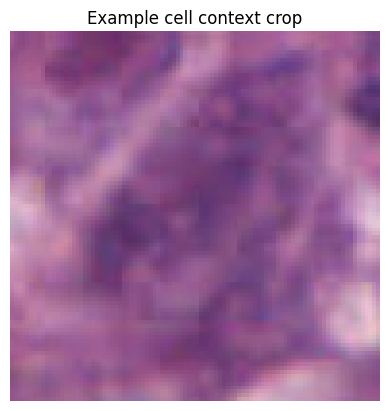

In [5]:
weights = ResNet18_Weights.DEFAULT
preprocess = weights.transforms()
encoder = resnet18(weights=weights)
encoder.fc = nn.Identity()
encoder = encoder.to(DEVICE).eval()
for parameter in encoder.parameters():
    parameter.requires_grad_(False)
CACHE_DIR = ROOT / f'processed/nucls/image_embeddings/resnet18_imagenet_v1_crop{CROP_SIZE}'
CACHE_DIR.mkdir(parents=True, exist_ok=True)

def crop_cell(image, cx, cy):
    half = CROP_SIZE // 2
    padded = np.pad(np.asarray(image), ((half, half), (half, half), (0, 0)), mode='reflect')
    left, top = int(round(cx)), int(round(cy))
    patch = padded[top:top + CROP_SIZE, left:left + CROP_SIZE]
    assert patch.shape == (CROP_SIZE, CROP_SIZE, 3), 'Cell center outside image.'
    return Image.fromarray(patch)

@torch.inference_mode()
def extract_embeddings(image_id, group):
    path = image_paths[image_id]
    signature = hashlib.sha256(
        group[['cell_id', 'center_x', 'center_y']].to_csv(index=False).encode()
        + str((path.stat().st_size, path.stat().st_mtime_ns)).encode()
    ).hexdigest()
    cache = CACHE_DIR / f'{image_id}.npz'
    if cache.exists():
        with np.load(cache, allow_pickle=False) as saved:
            if saved['signature'].item() == signature:
                return saved['x'].copy()
    with Image.open(path) as source:
        image = source.convert('RGB')
    centers = group[['center_x', 'center_y']].to_numpy()
    outputs = []
    for start in range(0, len(centers), EMBED_BATCH_SIZE):
        batch = torch.stack([preprocess(crop_cell(image, cx, cy))
                             for cx, cy in centers[start:start + EMBED_BATCH_SIZE]])
        outputs.append(encoder(batch.to(DEVICE)).cpu().numpy())
    features = np.concatenate(outputs).astype(np.float32)
    assert features.shape == (len(group), 512) and np.isfinite(features).all()
    np.savez_compressed(cache, x=features, signature=signature)
    return features

example = cells.iloc[0]
with Image.open(image_paths[example.image_id]) as source:
    plt.imshow(crop_cell(source.convert('RGB'), example.center_x, example.center_y))
plt.title('Example cell context crop'); plt.axis('off'); plt.show()

## 5. Spatial graphs

Each image becomes a graph. Cells connect to their five nearest neighbors within 120 pixels; reverse connections are added.

`X`: N x 512; `edge_index`: 2 x M; `edge_attr`: M x 1; `y`: N. Edge distances are divided by 120.

In [6]:
def make_edges(pos):
    if len(pos) < 2:
        return torch.empty((2, 0), dtype=torch.long), torch.empty((0, 1), dtype=torch.float32)
    distances, neighbors = NearestNeighbors(n_neighbors=min(K + 1, len(pos))).fit(pos).kneighbors(pos)
    pairs = set()
    for i in range(len(pos)):
        # Explicitly exclude self, including when cells have identical centers.
        candidates = [(float(d), int(j)) for d, j in zip(distances[i], neighbors[i]) if j != i][:K]
        for distance, j in candidates:
            if distance <= MAX_DISTANCE:
                pairs.update([(i, j), (j, i)])
    edges = np.asarray(sorted(pairs), dtype=np.int64).reshape(-1, 2)
    lengths = np.linalg.norm(pos[edges[:, 0]] - pos[edges[:, 1]], axis=1)
    return torch.from_numpy(edges.T.copy()), torch.tensor(lengths[:, None] / MAX_DISTANCE, dtype=torch.float32)

splits = {s: [] for s in split_frames}
for image_id, group in tqdm(cells.groupby('image_id', sort=True), desc='Embedding cells and building graphs'):
    pos = group[['center_x', 'center_y']].to_numpy(dtype=np.float32)
    edge_index, edge_attr = make_edges(pos)
    graph = Data(x=torch.from_numpy(extract_embeddings(image_id, group)),
                 pos=torch.from_numpy(pos), edge_index=edge_index, edge_attr=edge_attr,
                 y=torch.tensor(group.target.to_numpy(), dtype=torch.long),
                 cell_id=torch.tensor(group.cell_id.to_numpy(), dtype=torch.long), image_id=image_id)
    graph.validate(raise_on_error=True)
    splits[image_split[image_id]].append(graph)
print({s: len(gs) for s, gs in splits.items()})
del encoder
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

Embedding cells and building graphs:   0%|          | 0/1744 [00:00<?, ?it/s]

{'train': 1254, 'val': 190, 'test': 300}


## 6. Models

Feature normalization is fitted on training cells only.

- **MLP:** cell features alone.
- **GraphSAGE:** features and connectivity.
- **Graph transformer:** features, connectivity, and distances.

The MLP measures performance without spatial context. The transformer uses `TransformerConv`; it does not reproduce the published CGT architecture.

In [7]:
train_x = torch.cat([g.x for g in splits['train']])
feature_mean = train_x.mean(0)
feature_std = train_x.std(0, unbiased=False).clamp_min(1e-6)
for graphs in splits.values():
    for g in graphs:
        g.x = (g.x - feature_mean) / feature_std

class CellClassifier(nn.Module):
    def __init__(self, kind, in_dim=512, hidden=HIDDEN, n_classes=len(CLASSES)):
        super().__init__()
        if kind not in {'sage', 'transformer', 'mlp'}:
            raise ValueError(kind)
        self.kind = kind
        self.project = nn.Linear(in_dim, hidden)
        if kind == 'transformer':
            self.layers = nn.ModuleList([TransformerConv(hidden, hidden, heads=4, concat=False,
                                                         edge_dim=1, beta=True, dropout=0.1) for _ in range(2)])
        elif kind == 'sage':
            self.layers = nn.ModuleList([SAGEConv(hidden, hidden) for _ in range(2)])
        else:
            self.layers = nn.ModuleList([nn.Linear(hidden, hidden) for _ in range(2)])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(2)])
        self.classifier = nn.Linear(hidden, n_classes)

    def forward(self, batch):
        x = F.relu(self.project(batch.x))
        for layer, norm in zip(self.layers, self.norms):
            if self.kind == 'transformer':
                update = layer(x, batch.edge_index, batch.edge_attr)
            elif self.kind == 'sage':
                update = layer(x, batch.edge_index)
            else:
                update = layer(x)
            x = norm(x + F.dropout(F.relu(update), p=0.2, training=self.training))
        return self.classifier(x)

loaders = {s: DataLoader(gs, batch_size=GRAPH_BATCH_SIZE, shuffle=(s == 'train'), num_workers=0)
           for s, gs in splits.items()}
train_y = torch.cat([g.y for g in splits['train']])
counts = torch.bincount(train_y[train_y >= 0], minlength=len(CLASSES))
if (counts == 0).any():
    raise ValueError(f'Training classes absent: {[CLASSES[i] for i in (counts == 0).nonzero().flatten().tolist()]}. Increase subset or revise split.')
class_weights = counts.float().sum() / (len(CLASSES) * counts.float())
criterion = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))
model = CellClassifier(MODEL_KIND).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
print(model)

CellClassifier(
  (project): Linear(in_features=512, out_features=128, bias=True)
  (layers): ModuleList(
    (0-1): 2 x TransformerConv(128, 128, heads=4)
  )
  (norms): ModuleList(
    (0-1): 2 x LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (classifier): Linear(in_features=128, out_features=7, bias=True)
)


## 7. Training

Class-weighted loss accounts for label imbalance. The selected model maximizes validation macro-F1 across seven classes. The test set is reserved for final evaluation.

Epoch 01 | loss 1.4750 | validation macro-F1 0.3636
Epoch 02 | loss 1.1363 | validation macro-F1 0.3723
Epoch 03 | loss 0.9885 | validation macro-F1 0.3564
Epoch 04 | loss 0.8752 | validation macro-F1 0.3657
Epoch 05 | loss 0.7934 | validation macro-F1 0.3296
Epoch 06 | loss 0.6939 | validation macro-F1 0.3564
Epoch 07 | loss 0.6445 | validation macro-F1 0.3699
Epoch 08 | loss 0.5691 | validation macro-F1 0.3777
Epoch 09 | loss 0.5229 | validation macro-F1 0.3688
Epoch 10 | loss 0.4835 | validation macro-F1 0.3798
Epoch 11 | loss 0.4453 | validation macro-F1 0.3504
Epoch 12 | loss 0.4001 | validation macro-F1 0.3720
Epoch 13 | loss 0.3858 | validation macro-F1 0.3653
Epoch 14 | loss 0.3653 | validation macro-F1 0.3677
Epoch 15 | loss 0.3210 | validation macro-F1 0.3601
Epoch 16 | loss 0.2915 | validation macro-F1 0.3630
Epoch 17 | loss 0.2781 | validation macro-F1 0.3557
Epoch 18 | loss 0.2566 | validation macro-F1 0.3695
Epoch 19 | loss 0.2390 | validation macro-F1 0.3567
Epoch 20 | l

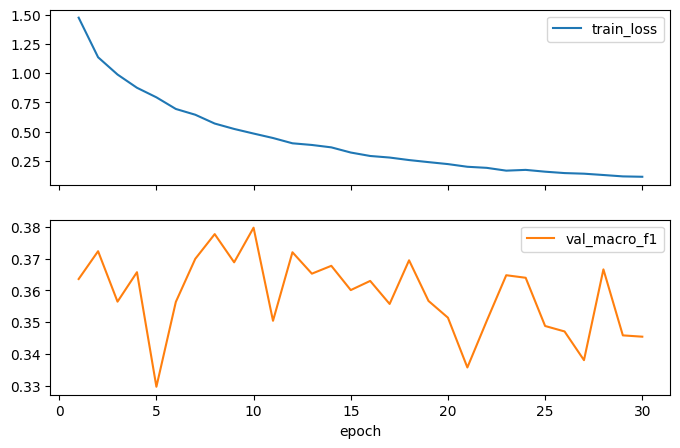

In [8]:
from sklearn.metrics import f1_score

@torch.inference_mode()
def evaluate(loader):
    model.eval()
    truth, predictions = [], []
    for batch in loader:
        batch = batch.to(DEVICE)
        mask = batch.y >= 0
        logits = model(batch)
        truth.extend(batch.y[mask].cpu().tolist())
        predictions.extend(logits[mask].argmax(1).cpu().tolist())
    if not truth:
        raise ValueError('No labeled cells in this split.')
    score = f1_score(truth, predictions, labels=list(range(len(CLASSES))), average='macro', zero_division=0)
    return score, np.array(truth), np.array(predictions)

best_score, best_state, history = -1.0, None, []
for epoch in range(1, EPOCHS + 1):
    model.train()
    loss_sum, labeled_count = 0.0, 0
    for batch in loaders['train']:
        batch = batch.to(DEVICE)
        mask = batch.y >= 0
        if not mask.any():
            continue
        optimizer.zero_grad()
        loss = criterion(model(batch)[mask], batch.y[mask])
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        n = int(mask.sum())
        loss_sum += float(loss.detach()) * n
        labeled_count += n
    val_f1, _, _ = evaluate(loaders['val'])
    history.append({'epoch': epoch, 'train_loss': loss_sum / max(labeled_count, 1), 'val_macro_f1': val_f1})
    if val_f1 > best_score:
        best_score = val_f1
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    print(f'Epoch {epoch:02d} | loss {history[-1]["train_loss"]:.4f} | validation macro-F1 {val_f1:.4f}')
assert best_state is not None
model.load_state_dict(best_state)
pd.DataFrame(history).to_csv(RUN_DIR / f'{MODEL_KIND}_history.csv', index=False)
pd.DataFrame(history).plot(x='epoch', y=['train_loss', 'val_macro_f1'], subplots=True, figsize=(8, 5)); plt.show()

## 8. Results and interpretation

Macro-F1 gives equal weight to each class. Recall measures how many annotated cells are correctly recovered; precision measures prediction reliability. Class support and the confusion matrix provide context.

The commentary below is generated from executed results. Scores describe classification of known cells, without assessing detection or segmentation.

Test macro-F1: 0.3692


,precision,recall,f1-score,support
tumor_nonMitotic,0.869090,0.813299,0.840270,3910.000000
tumor_mitotic,0.166667,0.135135,0.149254,37.000000
nonTILnonMQ_stromal,0.530375,0.587478,0.557468,1709.000000
macrophage,0.114919,0.280788,0.163090,203.000000
lymphocyte,0.406987,0.554432,0.469403,1681.000000
plasma_cell,0.519135,0.322481,0.397832,1935.000000
other_nucleus,0.010526,0.005263,0.007018,190.000000
accuracy,0.600414,0.600414,0.600414,0.600414
macro avg,0.373957,0.385554,0.369191,9665.000000
weighted avg,0.623354,0.600414,0.603932,9665.000000


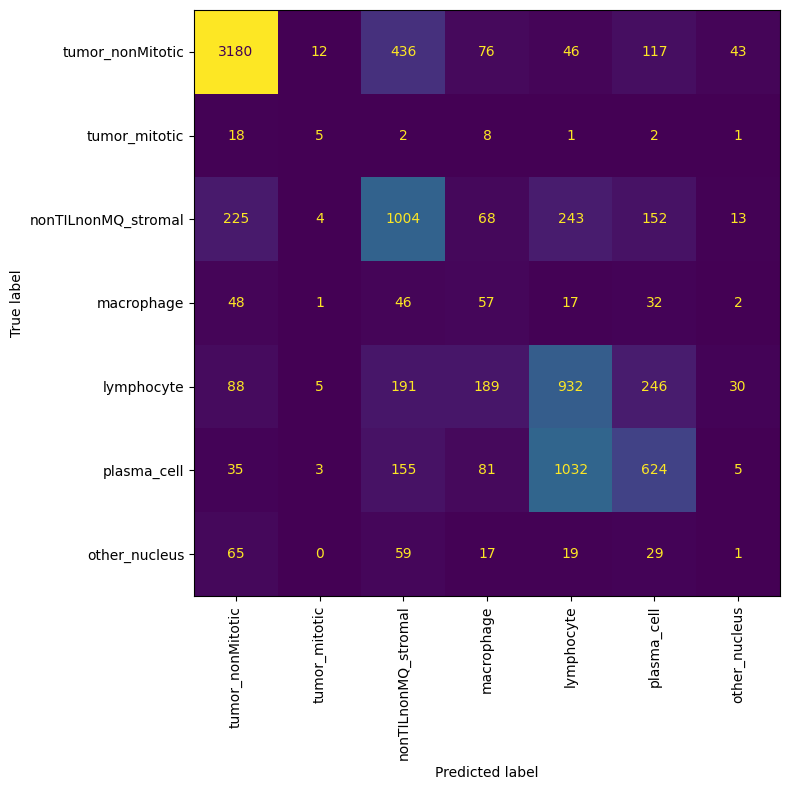

Saved results to c:\Users\Mahugnon\Documents\NuCLS\results\nucls_image_graph


In [9]:
test_f1, truth, predictions = evaluate(loaders['test'])
report = classification_report(truth, predictions, labels=list(range(len(CLASSES))),
                               target_names=CLASSES, output_dict=True, zero_division=0)
print('Test macro-F1:', round(test_f1, 4))
display(pd.DataFrame(report).T)
with open(RUN_DIR / f'{MODEL_KIND}_test_report.json', 'w') as f:
    json.dump(report, f, indent=2)
cm = confusion_matrix(truth, predictions, labels=list(range(len(CLASSES))))
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, xticks_rotation=90, colorbar=False)
plt.tight_layout(); plt.show()

torch.save({'state_dict': best_state, 'feature_mean': feature_mean, 'feature_std': feature_std,
            'classes': CLASSES, 'model_kind': MODEL_KIND, 'hidden': HIDDEN,
            'encoder': 'resnet18_imagenet1k_v1', 'crop_size': CROP_SIZE,
            'k': K, 'max_distance_pixels': MAX_DISTANCE, 'seed': SEED,
            'best_validation_macro_f1': best_score}, RUN_DIR / f'{MODEL_KIND}_best.pt')
print('Saved results to', RUN_DIR)

In [ ]:
from IPython.display import Markdown

supported = [name for name in CLASSES if report[name]['support'] > 0]
absent = [name for name in CLASSES if report[name]['support'] == 0]
best = max(supported, key=lambda name: report[name]['f1-score'])
weakest = min(supported, key=lambda name: report[name]['f1-score'])
best_epoch = max(history, key=lambda row: row['val_macro_f1'])['epoch']
lines = [
    f"**Results.** Test macro-F1 is **{test_f1:.3f}**, compared with "
    f"**{best_score:.3f}** on validation (checkpoint selected at epoch {best_epoch}).",
    f"Among classes present in the test set, **{best}** has the highest F1 "
    f"({report[best]['f1-score']:.3f}, n={int(report[best]['support'])}). "
    f"**{weakest}** has the lowest F1 "
    f"({report[weakest]['f1-score']:.3f}, n={int(report[weakest]['support'])})."
]
errors = cm.copy()
np.fill_diagonal(errors, 0)
if errors.sum():
    actual, predicted_class = np.unravel_index(errors.argmax(), errors.shape)
    lines.append(f"The most frequent confusion by count is **{CLASSES[actual]} -> "
                 f"{CLASSES[predicted_class]}** ({int(errors[actual, predicted_class])} cells). "
                 "Interpret this count alongside the number of cells in the true class.")
if absent:
    lines.append("Classes absent from the test set: " + ', '.join(absent) +
                 ". Their F1 is set to zero in macro-F1; their performance cannot be estimated.")
lines.append("These results cover one patient split. Model superiority requires "
             "a controlled comparison using the same split.")
display(Markdown('\n\n'.join(lines)))


## 9. Prediction review

Colors show predicted types on a test image. Inspect spatial patterns and compare predictions with annotations to identify errors.

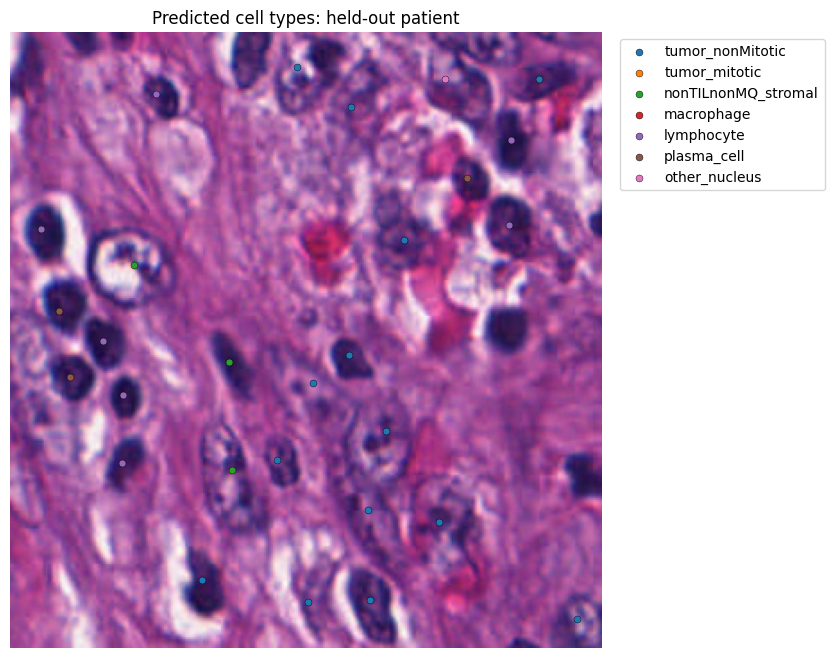

In [10]:
model.eval()
graph = splits['test'][0]
with torch.inference_mode():
    predicted = model(graph.clone().to(DEVICE)).argmax(1).cpu().numpy()
with Image.open(image_paths[graph.image_id]) as source:
    background = source.convert('RGB')
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(background)
positions = graph.pos.numpy()
for label_id, label in enumerate(CLASSES):
    selected = predicted == label_id
    ax.scatter(positions[selected, 0], positions[selected, 1], s=25,
               color=plt.get_cmap('tab10')(label_id), label=label, edgecolors='black', linewidths=0.3)
ax.set_title('Predicted cell types: held-out patient')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
ax.axis('off'); plt.show()
pd.DataFrame({'cell_id': graph.cell_id.numpy(), 'target_id': graph.y.numpy(),
              'predicted_type': [CLASSES[i] for i in predicted]}).to_csv(
    RUN_DIR / f'{MODEL_KIND}_example_predictions.csv', index=False)

## Further experiments

Compare all three models on the same patient split to measure the contribution of graph context. Then evaluate a pathology-specific encoder. Comparisons with published work require matching classes, annotations, and official folds.

References: [ResNet-18](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.resnet18), [TransformerConv](https://pytorch-geometric.readthedocs.io/en/2.6.1/generated/torch_geometric.nn.conv.TransformerConv.html).